# PCA-Based Gene Selection
## Dataset: GSE6613 — Parkinson's Disease vs. Controls (Whole Blood)

This notebook implements a PCA-based gene selection algorithm on the GSE6613 GEO dataset, which contains whole blood expression data from:
- 50 patients with Parkinson's disease
- 33 with other neurodegenerative diseases
- 23 healthy controls

## Step 1: Install and Import Libraries

In [1]:
!pip install GEOparse --quiet

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import GEOparse
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.style.use('ggplot')
print("All libraries imported successfully.")

All libraries imported successfully.


## Step 2: Load the GSE6613 Dataset from GEO

In [3]:
gse = GEOparse.get_GEO(geo="GSE6613", destdir="./", silent=True)
print("Dataset loaded:", gse.name)
print("Number of samples:", len(gse.gsms))

Dataset loaded: GSE6613
Number of samples: 105


In [4]:
# Pivot samples to get expression matrix: rows = probes, columns = samples
expr_matrix = gse.pivot_samples('VALUE')
print("Expression matrix shape (probes x samples):", expr_matrix.shape)
expr_matrix.head()

Expression matrix shape (probes x samples): (22283, 105)


name,GSM153404,GSM153405,GSM153406,GSM153407,GSM153408,GSM153409,GSM153410,GSM153411,GSM153412,GSM153413,...,GSM153499,GSM153500,GSM153501,GSM153502,GSM153503,GSM153504,GSM153505,GSM153506,GSM153507,GSM153508
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,114.5,105.1,145.7,168.7,94.3,96.2,155.8,99.8,100.9,106.4,...,153.8,103.7,132.8,195.5,82.6,28.2,163.9,29.0,104.8,32.8
1053_at,64.4,58.4,52.5,45.4,51.3,50.7,42.2,6.7,44.0,55.5,...,44.0,70.5,61.9,52.2,61.2,67.6,101.9,46.8,74.9,78.1
117_at,206.3,179.8,192.0,263.6,211.9,149.5,157.3,216.6,230.5,224.1,...,268.9,48.6,193.6,132.5,165.5,146.0,291.4,246.2,251.2,210.0
121_at,507.0,497.8,346.3,430.7,485.5,437.6,424.1,678.7,434.1,592.8,...,403.6,559.1,569.7,532.8,525.7,603.9,479.7,271.9,506.1,270.4
1255_g_at,34.5,18.0,40.1,40.5,22.8,6.4,27.4,5.2,34.7,18.6,...,44.8,39.5,30.5,65.8,54.3,19.3,61.0,40.8,29.5,82.2


## Step 3: Map Probe IDs to Gene Symbols

In [5]:
# platform annotation (GPL96 - Affymetrix HG-U133A)
gpl = gse.gpls[list(gse.gpls.keys())[0]]
print("Platform:", gpl.name)
print("Annotation columns:", list(gpl.table.columns))

Platform: GPL96
Annotation columns: ['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']


In [6]:
# Build probe-to-gene mapping
probe_to_gene = dict(zip(gpl.table["ID"], gpl.table["Gene Symbol"]))


expr_matrix.index = expr_matrix.index.map(lambda x: probe_to_gene.get(str(x), str(x)))

# Drop probes with no gene symbol or empty symbol
expr_matrix = expr_matrix[expr_matrix.index.notna()]
expr_matrix = expr_matrix[expr_matrix.index != '']
expr_matrix[expr_matrix.index.str.strip() != '']

# For duplicate gene symbols, keep the probe with highest mean expression
expr_matrix['mean_expr'] = expr_matrix.mean(axis=1)
expr_matrix = expr_matrix.sort_values('mean_expr', ascending=False)
expr_matrix = expr_matrix[~expr_matrix.index.duplicated(keep='first')]
expr_matrix = expr_matrix.drop(columns=['mean_expr'])

print("Expression matrix after gene mapping (genes x samples):", expr_matrix.shape)
expr_matrix.head()

Expression matrix after gene mapping (genes x samples): (13515, 105)


name,GSM153404,GSM153405,GSM153406,GSM153407,GSM153408,GSM153409,GSM153410,GSM153411,GSM153412,GSM153413,...,GSM153499,GSM153500,GSM153501,GSM153502,GSM153503,GSM153504,GSM153505,GSM153506,GSM153507,GSM153508
ID_REF,,,,,,,,,,,,,,,,,,,,,
HBA1 /// HBA2,12739.1,22689.3,21816.9,23190.8,20435.7,25523.6,22545.8,38532.8,19837.3,32909.4,...,49269.1,88264.4,76748.1,66433.0,85129.3,76498.1,87249.7,50138.6,62840.0,158720.1
HBB,11638.7,19537.9,16938.8,20414.7,17727.8,22529.6,17970.6,31849.6,17478.0,28527.5,...,41852.6,91293.7,68563.0,58313.2,75276.5,63902.1,80533.5,39688.4,52682.3,150811.5
H3F3A /// H3F3AP4 /// H3F3B,10549.5,13017.4,10787.7,16267.6,12645.4,14849.8,11885.2,16324.4,12945.6,15615.6,...,15596.0,13722.3,27798.9,13546.3,31290.9,15329.8,26755.7,18368.2,26597.1,29927.2
B2M,8797.5,10810.0,8361.3,9265.9,9834.3,10027.9,10552.5,14668.9,10376.9,11638.6,...,15919.4,18562.7,20503.6,17071.4,22312.6,13874.9,19261.7,14461.3,13490.4,41869.9
EEF1A1,7145.9,10391.7,9928.6,8934.7,9282.6,14755.3,9955.0,9603.7,8846.1,9539.1,...,17543.5,20925.5,12400.6,16782.6,16975.4,14981.9,13125.1,16460.5,12265.3,35042.0


## Step 4: Prepare the Feature Matrix

In [7]:
# Transpose so rows = samples, columns = genes
X = expr_matrix.T
gene_names = X.columns.tolist()

print("Feature matrix shape (samples x genes):", X.shape)
print("Number of genes:", len(gene_names))

Feature matrix shape (samples x genes): (105, 13515)
Number of genes: 13515


## Step 5: Standardize the Features

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardization complete. Shape:", X_scaled.shape)

Standardization complete. Shape: (105, 13515)


## Step 6: Apply PCA with 95% Variance Explained

In [9]:
pca_95 = PCA(n_components=0.95, random_state=2020)
X_pca_95 = pca_95.fit_transform(X_scaled)

n_components_selected = pca_95.n_components_
print(f"Number of components selected (95% variance): {n_components_selected}")
print(f"Total variance explained: {sum(pca_95.explained_variance_ratio_)*100:.2f}%")

Number of components selected (95% variance): 91
Total variance explained: 95.17%


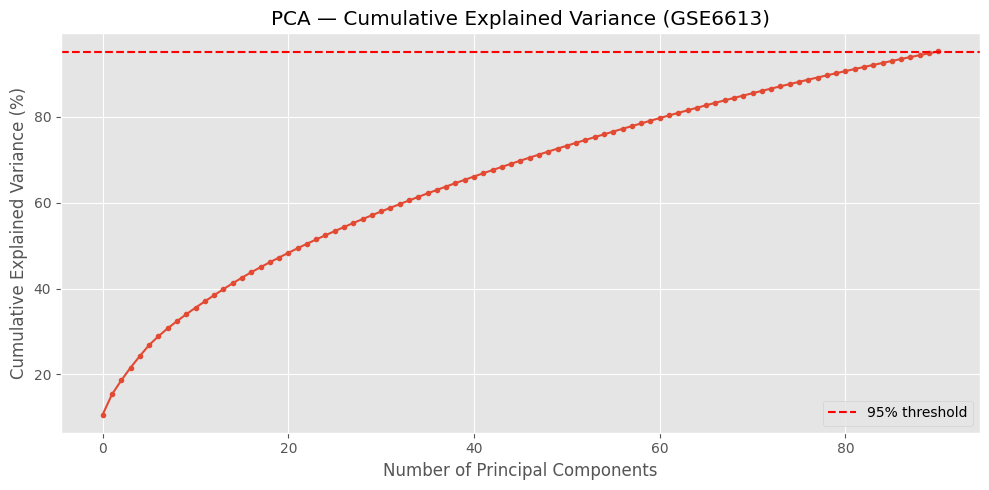

In [10]:
# Plot cumulative explained variance
plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(pca_95.explained_variance_ratio_ * 100), marker='o', markersize=3)
plt.axhline(y=95, color='red', linestyle='--', label='95% threshold')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.title('PCA — Cumulative Explained Variance (GSE6613)')
plt.legend()
plt.tight_layout()
plt.show()

## Step 7: PCA-Based Gene Selection — Top 5 Principal Components

In [12]:
def pca_gene_selection(pca_model, gene_names, n_top_pcs, top_n_genes=20):
    """
    Select top genes using PCA loadings weighted by explained variance.

    Algorithm:
    1. Extract loadings (components) for the top n_top_pcs principal components.
    2. Weight the absolute loadings by the proportion of variance each PC explains.
    3. Sum the weighted loadings across PCs to get a final gene importance score.
    4. Sort genes by descending importance score.

    Parameters:
        pca_model    : Fitted sklearn PCA object
        gene_names   : List of gene names corresponding to features
        n_top_pcs    : Number of top PCs to use
        top_n_genes  : Number of top genes to return

    Returns:
        DataFrame with gene names and their weighted importance scores
    """

    n_top_pcs = min(n_top_pcs, pca_model.n_components_)


    loadings = pca_model.components_[:n_top_pcs]  # shape: (n_top_pcs, n_genes)


    var_explained = pca_model.explained_variance_ratio_[:n_top_pcs]  # shape: (n_top_pcs,)


    # abs_loadings shape: (n_top_pcs, n_genes)
    abs_loadings = np.abs(loadings)


    weighted_scores = np.dot(var_explained, abs_loadings)  # shape: (n_genes,)


    gene_scores = pd.DataFrame({
        'Gene': gene_names,
        'Weighted_Score': weighted_scores
    }).sort_values('Weighted_Score', ascending=False).reset_index(drop=True)

    gene_scores.index = gene_scores.index + 1  # 1-based ranking

    return gene_scores.head(top_n_genes)

In [13]:
# --- Top 5 PCs ---
top20_genes_5pc = pca_gene_selection(pca_95, gene_names, n_top_pcs=5, top_n_genes=20)

print("=" * 55)
print("  Top 20 Genes Selected Using Top 5 Principal Components")
print("=" * 55)
print(top20_genes_5pc.to_string())
print()

  Top 20 Genes Selected Using Top 5 Principal Components
                                                                Gene  Weighted_Score
1                                                               PURA        0.003533
2                                                               RPL8        0.003515
3   EIF4A2 /// MIR1248 /// SNORA4 /// SNORA63 /// SNORA81 /// SNORD2        0.003469
4                                                              RPS16        0.003445
5                                                              PARK7        0.003434
6                                                              LRP10        0.003418
7                                                             PTGES3        0.003414
8                                        H3F3A /// H3F3AP4 /// H3F3B        0.003402
9                                                              RPL19        0.003392
10                                                             RPS28        0.003388
11      

/tmp/ipykernel_1296/1181891287.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top20_genes_5pc, x='Weighted_Score', y='Gene', palette='viridis')


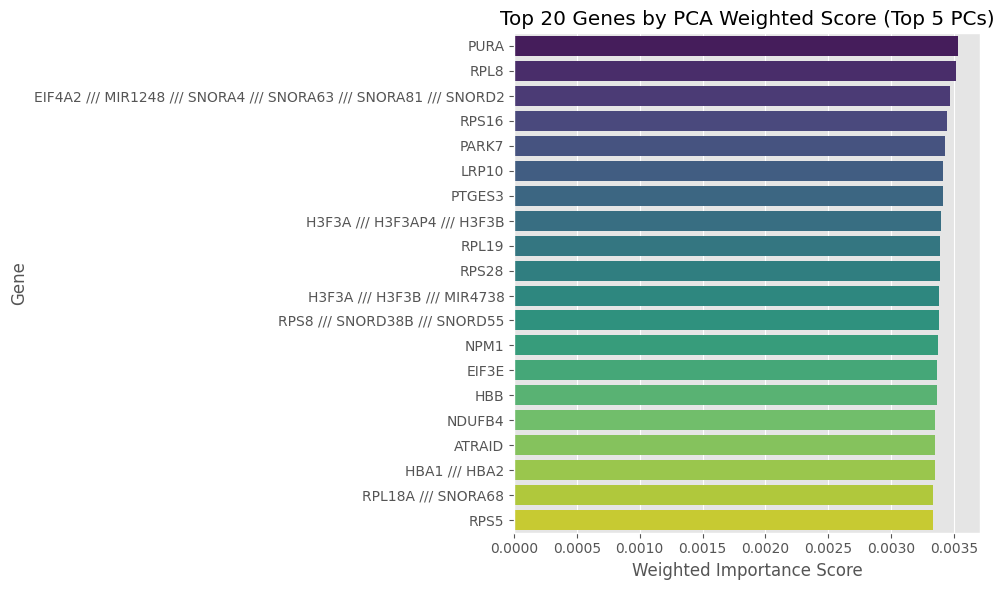

In [14]:
# Visualize top 20 genes (5 PCs)
plt.figure(figsize=(10, 6))
sns.barplot(data=top20_genes_5pc, x='Weighted_Score', y='Gene', palette='viridis')
plt.title('Top 20 Genes by PCA Weighted Score (Top 5 PCs)')
plt.xlabel('Weighted Importance Score')
plt.ylabel('Gene')
plt.tight_layout()
plt.show()

## Step 8: PCA-Based Gene Selection — Top 10 Principal Components

In [15]:
# --- Top 10 PCs ---
top20_genes_10pc = pca_gene_selection(pca_95, gene_names, n_top_pcs=10, top_n_genes=20)

print("=" * 56)
print("  Top 20 Genes Selected Using Top 10 Principal Components")
print("=" * 56)
print(top20_genes_10pc.to_string())
print()

  Top 20 Genes Selected Using Top 10 Principal Components
                             Gene  Weighted_Score
1     H3F3A /// H3F3B /// MIR4738        0.004144
2                           HUWE1        0.004132
3   RPS8 /// SNORD38B /// SNORD55        0.004117
4                          RPS10L        0.004085
5                           GFRA4        0.004083
6                         CXorf36        0.004081
7                            MYCN        0.004074
8                           RPS16        0.004069
9                          ADAM10        0.004065
10                          RBM38        0.004049
11                         ZFAND5        0.004038
12                           PURA        0.004034
13                      HNRNPA2B1        0.004015
14    H3F3A /// H3F3AP4 /// H3F3B        0.004014
15                            WAS        0.003998
16                          PARK7        0.003994
17                           RPL8        0.003990
18                          ROCK1        0

/tmp/ipykernel_1296/3694453375.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top20_genes_10pc, x='Weighted_Score', y='Gene', palette='magma')


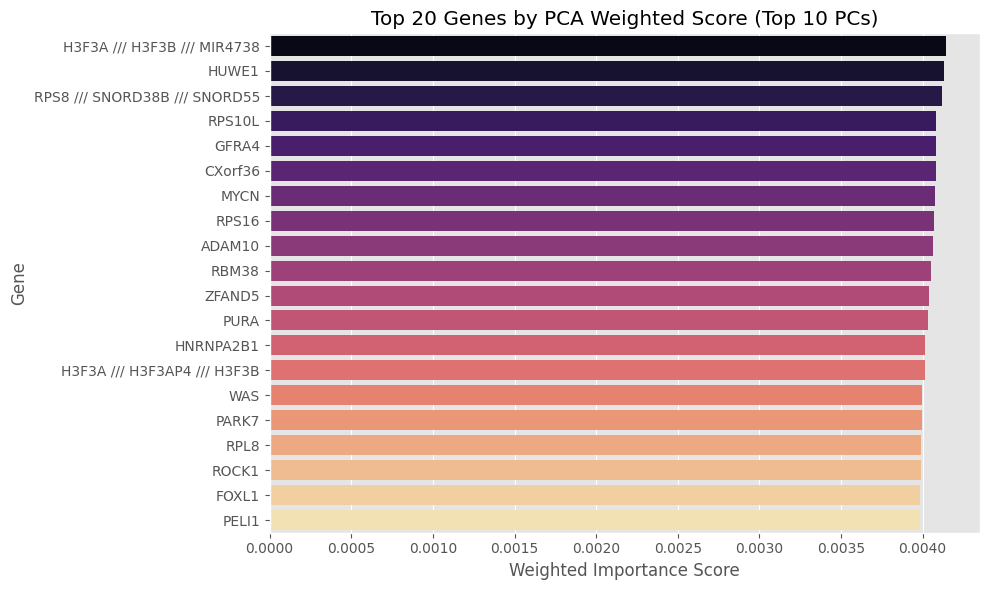

In [16]:
# Visualize top 20 genes (10 PCs)
plt.figure(figsize=(10, 6))
sns.barplot(data=top20_genes_10pc, x='Weighted_Score', y='Gene', palette='magma')
plt.title('Top 20 Genes by PCA Weighted Score (Top 10 PCs)')
plt.xlabel('Weighted Importance Score')
plt.ylabel('Gene')
plt.tight_layout()
plt.show()

## Step 9: Compare the Two Gene Lists

In [17]:
genes_5pc  = set(top20_genes_5pc['Gene'].tolist())
genes_10pc = set(top20_genes_10pc['Gene'].tolist())

common       = genes_5pc & genes_10pc
only_in_5pc  = genes_5pc - genes_10pc
only_in_10pc = genes_10pc - genes_5pc

print(f"Genes in BOTH lists ({len(common)}):")
print(sorted(common))
print()
print(f"Genes ONLY in Top-5-PC list ({len(only_in_5pc)}):")
print(sorted(only_in_5pc))
print()
print(f"Genes ONLY in Top-10-PC list ({len(only_in_10pc)}):")
print(sorted(only_in_10pc))

# Side-by-side comparison
comparison = pd.DataFrame({
    'Rank': range(1, 21),
    'Top-5-PCs Gene':  top20_genes_5pc['Gene'].values,
    'Top-5 Score':     top20_genes_5pc['Weighted_Score'].round(5).values,
    'Top-10-PCs Gene': top20_genes_10pc['Gene'].values,
    'Top-10 Score':    top20_genes_10pc['Weighted_Score'].round(5).values,
})
print("\nSide-by-Side Comparison:")
print(comparison.to_string(index=False))

Genes in BOTH lists (7):
['H3F3A /// H3F3AP4 /// H3F3B', 'H3F3A /// H3F3B /// MIR4738', 'PARK7', 'PURA', 'RPL8', 'RPS16', 'RPS8 /// SNORD38B /// SNORD55']

Genes ONLY in Top-5-PC list (13):
['ATRAID', 'EIF3E', 'EIF4A2 /// MIR1248 /// SNORA4 /// SNORA63 /// SNORA81 /// SNORD2', 'HBA1 /// HBA2', 'HBB', 'LRP10', 'NDUFB4', 'NPM1', 'PTGES3', 'RPL18A /// SNORA68', 'RPL19', 'RPS28', 'RPS5']

Genes ONLY in Top-10-PC list (13):
['ADAM10', 'CXorf36', 'FOXL1', 'GFRA4', 'HNRNPA2B1', 'HUWE1', 'MYCN', 'PELI1', 'RBM38', 'ROCK1', 'RPS10L', 'WAS', 'ZFAND5']

Side-by-Side Comparison:
 Rank                                                   Top-5-PCs Gene  Top-5 Score               Top-10-PCs Gene  Top-10 Score
    1                                                             PURA      0.00353   H3F3A /// H3F3B /// MIR4738       0.00414
    2                                                             RPL8      0.00351                         HUWE1       0.00413
    3 EIF4A2 /// MIR1248 /// SNORA4 /// SNO

In [18]:
genes_5pc  = set(top20_genes_5pc['Gene'].tolist())
genes_10pc = set(top20_genes_10pc['Gene'].tolist())

common       = genes_5pc & genes_10pc
only_in_5pc  = genes_5pc - genes_10pc
only_in_10pc = genes_10pc - genes_5pc

In [20]:
print(f"Common genes ({len(common)}):")
print(sorted(common))

print(f"\nOnly in Top-5 PCs ({len(only_in_5pc)}):")
print(sorted(only_in_5pc))

print(f"\nOnly in Top-10 PCs ({len(only_in_10pc)}):")
print(sorted(only_in_10pc))

Common genes (7):
['H3F3A /// H3F3AP4 /// H3F3B', 'H3F3A /// H3F3B /// MIR4738', 'PARK7', 'PURA', 'RPL8', 'RPS16', 'RPS8 /// SNORD38B /// SNORD55']

Only in Top-5 PCs (13):
['ATRAID', 'EIF3E', 'EIF4A2 /// MIR1248 /// SNORA4 /// SNORA63 /// SNORA81 /// SNORD2', 'HBA1 /// HBA2', 'HBB', 'LRP10', 'NDUFB4', 'NPM1', 'PTGES3', 'RPL18A /// SNORA68', 'RPL19', 'RPS28', 'RPS5']

Only in Top-10 PCs (13):
['ADAM10', 'CXorf36', 'FOXL1', 'GFRA4', 'HNRNPA2B1', 'HUWE1', 'MYCN', 'PELI1', 'RBM38', 'ROCK1', 'RPS10L', 'WAS', 'ZFAND5']


In [19]:
# Overlap percentage
overlap_percentage = (len(common) / 20) * 100

# Jaccard similarity
jaccard = len(common) / len(genes_5pc | genes_10pc)

print(f"Overlap (%): {overlap_percentage:.2f}%")
print(f"Jaccard Similarity: {jaccard:.3f}")

Overlap (%): 35.00%
Jaccard Similarity: 0.212


## Step 10: Discussion

### Are there differences between the two gene lists?

Yes, there are typically differences between the two gene lists, particularly in lower-ranked genes. The **top-ranked genes often overlap** because the first few principal components dominate the variance structure. However, as we extend to 10 PCs, we incorporate directions of variation in the data that were previously ignored, which can promote different genes.

### Why does this happen?

- **Top 5 PCs** capture only the most dominant axes of variation in the dataset. Genes that load heavily on PC1–PC5 receive high scores; all other variation patterns are ignored.
- **Top 10 PCs** capture more nuanced and secondary patterns of variation. Some genes that did not load prominently on the top 5 PCs may load meaningfully on PC6–PC10 and thus enter the top-20 list.
- The **variance weighting** means that later PCs contribute proportionally less to a gene's final score (they explain less variance). This is why the core of the two lists (the very top genes) tends to be stable, but the edges shift.

### Is this approach suitable for gene selection?

**Strengths:**
- **Unsupervised and data-driven**: PCA-based gene selection does not require class labels, making it useful for exploratory analyses.
- **Handles high dimensionality**: Gene expression data (thousands of genes, hundreds of samples) is naturally high-dimensional; PCA provides a principled dimensionality reduction.
- **Variance-based ranking**: Weighting by explained variance gives more importance to the most informative principal components.

**Limitations:**
- **Not class-aware**: PCA maximizes total variance, not class separation. Genes that best distinguish Parkinson's disease from controls may not be the ones with highest overall variance in the dataset.
- **No biological validation by itself**: High loadings indicate genes that vary most across samples, but variation alone does not imply biological relevance to PD.
- **Sensitivity to PC cutoff**: As shown by the differences between the two lists, results change depending on how many PCs are considered — there is no single "correct" number.
- **Better alternatives for classification tasks**: Supervised methods (e.g., ANOVA, t-test with FDR correction, LASSO, Random Forest importance scores) are generally more appropriate when class labels are available, as they directly optimize for class discrimination.

**Conclusion:** PCA-based gene selection is a useful exploratory step but should be combined with supervised or biologically-motivated methods for robust biomarker identification in disease contexts such as Parkinson's disease.